In [159]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spikeinterface.extractors as se
import spikeinterface as si

PLX_FILE = r"D:\raw_data\orga_pre_exp\20260928\plx\subjects_2.exps_29.origin.20260928131241_565310.20260928__ce.00000.mex_20260928_181616\subjects_2.exps_29.origin.20260928131241_565310.20260928__ce.00000.plx"

recording = se.read_plexon(PLX_FILE)

print(recording)

fs = recording.get_sampling_frequency()
channel_ids = recording.get_channel_ids()
duration = recording.get_num_samples() / fs

print("\nSampling frequency:", fs)
print("Channels:", channel_ids)
print("Duration:", duration, "s")

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 710083276.15it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<?, ?it/s]

PlexonRecordingExtractor: 15 channels - 30.0kHz - 1 segments - 5,547,393 samples 
                          184.91s (3.08 minutes) - int16 dtype - 158.71 MiB
  file_path: D:\raw_data\orga_pre_exp\20260928\plx\subjects_2.exps_29.origin.20260928131241_565310.20260928__ce.00000.mex_20260928_181616\subjects_2.exps_29.origin.20260928131241_565310.20260928__ce.00000.plx

Sampling frequency: 30000.0
Channels: ['WB000' 'WB001' 'WB002' 'WB003' 'WB004' 'WB005' 'WB006' 'WB007' 'WB008'
 'WB009' 'WB010' 'WB011' 'WB012' 'WB013' 'WB014']
Duration: 184.9131 s


In [160]:
from pathlib import Path
import struct

plx_path = Path(PLX_FILE)

with plx_path.open("rb") as f:
    # 全局文件头固定为 7504 字节
    header = f.read(7504)
    if len(header) != 7504:
        raise ValueError("PLX 文件头不完整")

    magic, version = struct.unpack_from("<Ii", header, 0)
    if magic != 0x58454C50:
        raise ValueError("不是有效的 PLX 文件")
    if version != 106:
        raise ValueError(f"此示例针对版本 106，当前版本为 {version}")

    # '<' 表示小端字节序
    # i: 4 字节有符号整数；B: 1 字节无符号整数
    # H: 2 字节无符号整数
    timestamp_frequency, n_dsp, n_event, n_slow = (
        struct.unpack_from("<4i", header, 136)
    )

    bits_spike = struct.unpack_from("<B", header, 202)[0]
    bits_slow = struct.unpack_from("<B", header, 203)[0]
    slow_max_mV = struct.unpack_from("<H", header, 206)[0]

    print("Version:", version)
    print("TimestampFrequency:", timestamp_frequency)
    print("BitsPerSpikeSample:", bits_spike)
    print("BitsPerSlowSample:", bits_slow)
    print("SlowMaxMagnitudeMV:", slow_max_mV)
    print("NumSlowChannels:", n_slow)

    # 连续通道头位于 DSP 通道头和事件通道头之后
    # DSP 通道头：1020 字节；事件通道头：296 字节
    slow_header_start = 7504 + n_dsp * 1020 + n_event * 296
    f.seek(slow_header_start)

    for _ in range(n_slow):
        channel_header = f.read(296)
        if len(channel_header) != 296:
            raise ValueError("连续通道头不完整")

        name = (
            channel_header[:32]
            .split(b"\x00", 1)[0]
            .decode("ascii", errors="replace")
        )

        channel, sample_rate, gain, enabled, preamp_gain = (
            struct.unpack_from("<5i", channel_header, 32)
        )

        # 按连续通道头计算，单位为 µV/count
        gain_uV = (
            slow_max_mV * 1000
            / (2 ** (bits_slow - 1) * gain * preamp_gain)
        )

        print(
            f"{name}: channel={channel}, "
            f"sample_rate={sample_rate}, "
            f"Gain={gain}, PreampGain={preamp_gain}, "
            f"gain_uV={gain_uV:.11f}"
        )

Version: 106
TimestampFrequency: 30000
BitsPerSpikeSample: 12
BitsPerSlowSample: 12
SlowMaxMagnitudeMV: 3994
NumSlowChannels: 15
WB000: channel=0, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB001: channel=1, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB002: channel=2, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB003: channel=3, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB004: channel=4, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB005: channel=5, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB006: channel=6, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB007: channel=7, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB008: channel=8, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB009: channel=9, sample_rate=30000, Gain=1, PreampGain=10000, gain_uV=0.19501953125
WB010: channel=10, sa

In [161]:
n = recording.get_num_channels()

# Neo 的源物理单位及对应系数
recording.delete_property("physical_unit")
recording.delete_property("gain_to_physical_unit")
recording.delete_property("offset_to_physical_unit")

# SpikeInterface 用于输出 µV 的系数
recording.set_channel_gains(np.full(n, 0.19501953125))
recording.set_channel_offsets(np.zeros(n))

In [162]:
print("SpikeInterface properties:")
print(recording.get_property_keys())
print(recording.get_dtype())
print(recording.get_property("physical_unit"))
import numpy as np
print("\ngain_to_uV:")
print(np.unique(recording.get_property("gain_to_uV")))

print("\noffset_to_uV:")
print(np.unique(recording.get_property("offset_to_uV")))

print("\nelectrode:")
print(recording.get_property("electrode"))

SpikeInterface properties:
['gain_to_uV', 'offset_to_uV']
int16
None

gain_to_uV:
[0.19501953]

offset_to_uV:
[0.]

electrode:
None


In [163]:
# ============================================================
# 设置 dummy channel locations
# Mountainsort5 要求 recording 具有 channel locations
# 这里每个 group 独立 sorting，因此坐标仅用于满足接口要求
# ============================================================

n = recording.get_num_channels()

dummy_locations = np.zeros(
    (n, 2),
    dtype=float
)

# 给不同通道一个简单的虚拟 x 坐标
dummy_locations[:, 0] = np.arange(n)

recording.set_channel_locations(
    dummy_locations
)

print(
    recording.get_channel_locations()
)

[[ 0.  0.]
 [ 1.  0.]
 [ 2.  0.]
 [ 3.  0.]
 [ 4.  0.]
 [ 5.  0.]
 [ 6.  0.]
 [ 7.  0.]
 [ 8.  0.]
 [ 9.  0.]
 [10.  0.]
 [11.  0.]
 [12.  0.]
 [13.  0.]
 [14.  0.]]


C:\Users\Bin\AppData\Local\Temp\ipykernel_12196\67789547.py:17: FutureWarning: set_channel_locations() is deprecated and will be removed in version 0.106.0. If you want to set probe information, use `set_dummy_probe_from_locations()`.
  recording.set_channel_locations(


In [164]:
#group
import numpy as np

n = recording.get_num_channels()
channel_ids = recording.get_channel_ids()

# 直接覆盖 group 属性
recording.set_property("group", np.arange(n))

# 验证
print(recording.get_property("group"))
# 应该输出 [0 1 2 3 4 5 6 7 8 9 10 11 12 13 14]

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [165]:
import spikeinterface.preprocessing as spre

# ============================================================
# Spike-band filtering
# ============================================================

recording_filtered = spre.bandpass_filter(
    recording,
    freq_min=300,
    freq_max=6000
)

print(recording_filtered)
print(
    "Sampling frequency:",
    recording_filtered.get_sampling_frequency()
)
print(
    "Number of channels:",
    recording_filtered.get_num_channels()
)
print(
    "Number of frames:",
    recording_filtered.get_num_frames()
)

# 确认 group 属性仍然存在
print(
    "Groups:",
    recording_filtered.get_property("group")
)

BandpassFilterRecording: 15 channels - 30.0kHz - 1 segments - 5,547,393 samples 
                         184.91s (3.08 minutes) - int16 dtype - 158.71 MiB
Sampling frequency: 30000.0
Number of channels: 15
Number of frames: 5547393
Groups: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [166]:
# ========== Cell 6: 滤波信号存内存 + 拆分 ==========
recording_mem = recording_filtered.save_to_memory()
recording_dict = recording_mem.split_by("group", outputs="dict")

c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\core\base.py:838: FutureWarning: save_to_memory() should be save(format='memory')
  warnings.warn("save_to_memory() should be save(format='memory')", FutureWarning)
write_memory (no parallelization): 100%|██████████| 185/185 [00:01<00:00, 113.22it/s]


In [1]:
#查看mountainsorter5的default parameters
import spikeinterface.sorters as ss

# 获取 MountainSort5 的默认参数字典
default_params = ss.get_default_sorter_params('mountainsort5')
print(default_params)

c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'scheme': '2', 'detect_threshold': 5.5, 'detect_sign': -1, 'detect_time_radius_msec': 0.5, 'snippet_T1': 20, 'snippet_T2': 20, 'npca_per_channel': 3, 'npca_per_subdivision': 10, 'snippet_mask_radius': 250, 'scheme1_detect_channel_radius': 150, 'scheme2_phase1_detect_channel_radius': 200, 'scheme2_detect_channel_radius': 50, 'scheme2_max_num_snippets_per_training_batch': 200, 'scheme2_training_duration_sec': 300, 'scheme2_training_recording_sampling_mode': 'uniform', 'scheme3_block_duration_sec': 1800, 'freq_min': 300, 'freq_max': 6000, 'filter': True, 'whiten': True, 'whitening_seed': None, 'delete_temporary_recording': True, 'pool_engine': 'process', 'n_jobs': 1, 'chunk_duration': '1s', 'progress_bar': True, 'mp_context': None, 'max_threads_per_worker': 1}


In [167]:
from spikeinterface import sorters as ss
# ========== Cell 4: sorting ==========
sorting_test = ss.run_sorter_by_property(
    sorter_name="mountainsort5",
    recording=recording_filtered,
    grouping_property="group",
    folder="ms5_by_channel_filtered",
    remove_existing_folder=True
)
print(sorting_test)

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 659658562.30it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<00:00, 67769.62it/s]


Using training recording of duration 300 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 0.000 seconds ***
Running phase 1 sorting
Number of channels: 1
Number of timepoints: 5547393
Sampling frequency: 30000.0 Hz
Channel 0: [0. 0.]
Loading traces
*** MS5 Elapsed time for load_traces: 0.000 seconds ***
Detecting spikes

Adjacency for detect spikes with channel radius 200
[[0]]

m = 0 (nbhd size: 1)
Detected 12 spikes
*** MS5 Elapsed time for detect_spikes: 0.033 seconds ***
Removing duplicate times
*** MS5 Elapsed time for remove_duplicate_times: 0.000 seconds ***
Extracting 12 snippets
*** MS5 Elapsed time for extract_snippets: 0.000 seconds ***
Computing PCA features with npca=3
*** MS5 Elapsed time for compute_pca_features: 0.003 seconds ***
Isosplit6 clustering with npca_per_subdivision=10
Found 1 clusters
*** MS5 Elapsed time for isosplit6_subdivision_method: 0.000 seconds ***
Computing templates
*** MS5 Elapsed time for comp

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 656492248.66it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 651249388.37it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<?, ?it/s]


Using training recording of duration 300 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 0.000 seconds ***
Running phase 1 sorting
Number of channels: 1
Number of timepoints: 5547393
Sampling frequency: 30000.0 Hz
Channel 0: [1. 0.]
Loading traces
*** MS5 Elapsed time for load_traces: 0.000 seconds ***
Detecting spikes

Adjacency for detect spikes with channel radius 200
[[0]]

m = 0 (nbhd size: 1)
Detected 53 spikes
*** MS5 Elapsed time for detect_spikes: 0.032 seconds ***
Removing duplicate times
*** MS5 Elapsed time for remove_duplicate_times: 0.000 seconds ***
Extracting 53 snippets
*** MS5 Elapsed time for extract_snippets: 0.000 seconds ***
Computing PCA features with npca=3
*** MS5 Elapsed time for compute_pca_features: 0.002 seconds ***
Isosplit6 clustering with npca_per_subdivision=10
Found 1 clusters
*** MS5 Elapsed time for isosplit6_subdivision_method: 0.000 seconds ***
Computing templates
*** MS5 Elapsed time for comp

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 641617758.45it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 661960862.57it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<?, ?it/s]


...

Using training recording of duration 300 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 0.000 seconds ***
Running phase 1 sorting
Number of channels: 1
Number of timepoints: 5547393
Sampling frequency: 30000.0 Hz
Channel 0: [13.  0.]
Loading traces
*** MS5 Elapsed time for load_traces: 0.000 seconds ***
Detecting spikes

Adjacency for detect spikes with channel radius 200
[[0]]

m = 0 (nbhd size: 1)
Detected 1 spikes
*** MS5 Elapsed time for detect_spikes: 0.036 seconds ***
Removing duplicate times
*** MS5 Elapsed time for remove_duplicate_times: 0.000 seconds ***
Extracting 1 snippets
*** MS5 Elapsed time for extract_snippets: 0.000 seconds ***
Computing PCA features with npca=3
*** MS5 Elapsed time for compute_pca_features: 0.000 seconds ***
Isosplit6 clustering with npca_per_subdivision=10
Found 1 clusters
*** MS5 Elapsed time for isosplit6_subdivision_method: 0.002 seconds ***
Computing templates
*** MS5 Elapsed time for comp

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 658132778.00it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 654239980.84it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<?, ?it/s]


Using training recording of duration 300 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 0.000 seconds ***
Running phase 1 sorting
Number of channels: 1
Number of timepoints: 5547393
Sampling frequency: 30000.0 Hz
Channel 0: [14.  0.]
Loading traces
*** MS5 Elapsed time for load_traces: 0.000 seconds ***
Detecting spikes

Adjacency for detect spikes with channel radius 200
[[0]]

m = 0 (nbhd size: 1)
Detected 120 spikes
*** MS5 Elapsed time for detect_spikes: 0.033 seconds ***
Removing duplicate times
*** MS5 Elapsed time for remove_duplicate_times: 0.000 seconds ***
Extracting 120 snippets
*** MS5 Elapsed time for extract_snippets: 0.000 seconds ***
Computing PCA features with npca=3
*** MS5 Elapsed time for compute_pca_features: 0.000 seconds ***
Isosplit6 clustering with npca_per_subdivision=10
Found 1 clusters
*** MS5 Elapsed time for isosplit6_subdivision_method: 0.000 seconds ***
Computing templates
*** MS5 Elapsed time for 

Parsing data blocks: 100%|█████████▉| 167087550/167118438 [00:00<00:00, 702850027.29it/s]
Finalizing data blocks for type 1: 0it [00:00, ?it/s], ?it/s]
Parsing signal channels: 100%|██████████| 15/15 [00:00<?, ?it/s]
Parsing spike channels: 0it [00:00, ?it/s]
Parsing event channels: 100%|██████████| 64/64 [00:00<?, ?it/s]

UnitsAggregationSorting: 11 units - 1 segments - 30.0kHz


In [168]:
# ========== Cell 7: 创建 analyzer ==========
analyzers_by_group = {}
unit_groups = sorting_test.get_property("group")

for group_id, sub_rec in recording_dict.items():
    unit_ids_in_group = [
        uid for uid, g in zip(sorting_test.get_unit_ids(), unit_groups)
        if g == group_id
    ]
    if len(unit_ids_in_group) == 0:
        continue

    sorting_sub = sorting_test.select_units(unit_ids_in_group)

    analyzer_sub = si.create_sorting_analyzer(
        sorting=sorting_sub,
        recording=sub_rec,
        format="memory"
    )
    analyzers_by_group[group_id] = analyzer_sub

estimate_templates (no parallelization): 100%|██████████| 185/185 [00:00<00:00, 184837.12it/s]


In [169]:
import pandas as pd

qc_results = {}

for group_id, analyzer in analyzers_by_group.items():

    print("\n" + "=" * 60)
    print(f"Computing QC for group {group_id}")

    # --------------------------------
    # 1. Analyzer extensions
    # --------------------------------

    analyzer.compute("random_spikes")

    analyzer.compute(
        "waveforms",
        ms_before=1.0,
        ms_after=2.0
    )

    analyzer.compute("templates")

    analyzer.compute("noise_levels")

    analyzer.compute("spike_amplitudes")

    # --------------------------------
    # 2. Quality metrics
    # --------------------------------

    analyzer.compute(
        "quality_metrics",
        metric_names=[
            "num_spikes",
            "firing_rate",
            "presence_ratio",
            "snr",
            "amplitude_median",
            "amplitude_cutoff",
            "isi_violation",
        ]
    )

    qm = analyzer.get_extension(
        "quality_metrics"
    ).get_data()

    qm["group"] = group_id

    qc_results[group_id] = qm

    print(qm)


Computing QC for group 0


spike_amplitudes (no parallelization): 100%|██████████| 185/185 [00:00<00:00, 56962.73it/s]
c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\metrics\quality\misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.uint64(0)]: too few spikes (< 500).
  warnings.warn(


   num_spikes  firing_rate  presence_ratio       snr  amplitude_median  \
0          11     0.059487             1.0  6.306918        -15.796582   

   amplitude_cutoff  isi_violations_ratio  isi_violations_count  group  
0               NaN                   0.0                     0      0  

Computing QC for group 1


spike_amplitudes (no parallelization): 100%|██████████| 185/185 [00:00<00:00, 31825.86it/s]
c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\metrics\quality\misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.uint64(1)]: too few spikes (< 500).
  warnings.warn(


   num_spikes  firing_rate  presence_ratio      snr  amplitude_median  \
1          53     0.286621             1.0  7.01194        -11.701172   

   amplitude_cutoff  isi_violations_ratio  isi_violations_count  group  
1               NaN                   0.0                     0      1  

Computing QC for group 2


...

spike_amplitudes (no parallelization): 100%|██████████| 185/185 [00:00<00:00, 43668.54it/s]
c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\metrics\quality\misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.uint64(9)]: too few spikes (< 500).
  warnings.warn(


   num_spikes  firing_rate  presence_ratio     snr  amplitude_median  \
9          61     0.329885             1.0  6.7776        -13.651367   

   amplitude_cutoff  isi_violations_ratio  isi_violations_count  group  
9               NaN                   0.0                     0     12  

Computing QC for group 14


spike_amplitudes (no parallelization): 100%|██████████| 185/185 [00:00<00:00, 35113.87it/s]

    num_spikes  firing_rate  presence_ratio       snr  amplitude_median  \
10         119     0.643546             1.0  6.941389        -11.311132   

    amplitude_cutoff  isi_violations_ratio  isi_violations_count  group  
10               NaN                   0.0                     0     14  



c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\metrics\quality\misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.uint64(10)]: too few spikes (< 500).
  warnings.warn(


In [170]:
import pandas as pd

qc_table = pd.concat(
    qc_results.values(),
    axis=0
)

# unit ID 当前存储在 DataFrame index 中
qc_table.index.name = "unit_id"

# 把 unit_id 从 index 转成普通列
qc_table = qc_table.reset_index()

print(qc_table)

    unit_id  num_spikes  firing_rate  presence_ratio       snr  \
0         0          11     0.059487        1.000000  6.306918   
1         1          53     0.286621        1.000000  7.011940   
2         2          11     0.059487        1.000000  5.911612   
3         3          61     0.329885        1.000000  6.875728   
4         4          76     0.411004        1.000000  6.784491   
5         5          56     0.302845        1.000000  7.266671   
6         6           2     0.010816        0.666667  6.503048   
7         7          36     0.194686        1.000000  7.075067   
8         8          30     0.162238        1.000000  6.710084   
9         9          61     0.329885        1.000000  6.777600   
10       10         119     0.643546        1.000000  6.941389   

    amplitude_median  amplitude_cutoff  isi_violations_ratio  \
0         -15.796582               NaN                   0.0   
1         -11.701172               NaN                   0.0   
2         -16.3

In [171]:
# ================================================
# QC thresholds
# ================================================

MIN_SPIKES = 20
MIN_FIRING_RATE = 0.1
MIN_PRESENCE_RATIO = 0.8

MIN_SNR = 4.0

MAX_ISI_VIOLATION_RATIO = 0.01
MIN_SPIKES_FOR_ISI = 50


# ================================================
# Part 1 — Basic activity QC
# ================================================

qc_table["basic_qc"] = (
    (qc_table["num_spikes"] >= MIN_SPIKES)
    & (qc_table["firing_rate"] >= MIN_FIRING_RATE)
    & (qc_table["presence_ratio"] >= MIN_PRESENCE_RATIO)
)


# ================================================
# Part 2 — Signal / waveform QC
# ================================================

qc_table["signal_qc"] = (
    qc_table["snr"] >= MIN_SNR
)

# amplitude_cutoff:
# 当前所有 unit <500 spikes，因此不参与硬筛选


# ================================================
# Part 3 — Physiological QC
# ================================================

qc_table["physiology_qc"] = (
    qc_table["isi_violations_ratio"]
    <= MAX_ISI_VIOLATION_RATIO
)

qc_table["isi_reliable"] = (
    qc_table["num_spikes"] >= MIN_SPIKES_FOR_ISI
)


# ================================================
# Final QC
# ================================================

qc_table["pass_all"] = (
    qc_table["basic_qc"]
    & qc_table["signal_qc"]
    & qc_table["physiology_qc"]
)


# ================================================
# Failure reasons
# ================================================

def get_failure_reason(row):

    reasons = []

    if row["num_spikes"] < MIN_SPIKES:
        reasons.append("too_few_spikes")

    if row["firing_rate"] < MIN_FIRING_RATE:
        reasons.append("low_firing_rate")

    if row["presence_ratio"] < MIN_PRESENCE_RATIO:
        reasons.append("low_presence_ratio")

    if row["snr"] < MIN_SNR:
        reasons.append("low_snr")

    if row["isi_violations_ratio"] > MAX_ISI_VIOLATION_RATIO:
        reasons.append("high_isi_violation")

    if len(reasons) == 0:
        return "PASS"

    return "; ".join(reasons)


qc_table["failure_reason"] = qc_table.apply(
    get_failure_reason,
    axis=1
)


# ================================================
# Display
# ================================================

columns = [
    "group",
    "unit_id",
    "num_spikes",
    "firing_rate",
    "presence_ratio",
    "snr",
    "amplitude_median",
    "isi_violations_ratio",
    "basic_qc",
    "signal_qc",
    "physiology_qc",
    "isi_reliable",
    "pass_all",
    "failure_reason",
]

# unit_id 可能是 index，而不是普通 column
available_columns = [
    c for c in columns
    if c in qc_table.columns
]

print(
    qc_table[available_columns].to_string(index=False)
)

 group  unit_id  num_spikes  firing_rate  presence_ratio      snr  amplitude_median  isi_violations_ratio  basic_qc  signal_qc  physiology_qc  isi_reliable  pass_all                                      failure_reason
     0        0          11     0.059487        1.000000 6.306918        -15.796582                   0.0     False       True           True         False     False                     too_few_spikes; low_firing_rate
     1        1          53     0.286621        1.000000 7.011940        -11.701172                   0.0      True       True           True          True      True                                                PASS
     2        2          11     0.059487        1.000000 5.911612        -16.381641                   0.0     False       True           True         False     False                     too_few_spikes; low_firing_rate
     3        3          61     0.329885        1.000000 6.875728        -12.481250                   0.0      True       True  

In [172]:
def classify_unit(row):

    if not row["basic_qc"]:
        return "FAIL"

    if not row["signal_qc"]:
        return "FAIL"

    if not row["physiology_qc"]:
        return "FAIL"

    if not row["isi_reliable"]:
        return "PASS_LOW_CONFIDENCE"

    return "PASS"


qc_table["qc_status"] = qc_table.apply(
    classify_unit,
    axis=1
)

print(
    qc_table[
        ["group", "unit_id", "qc_status", "failure_reason"]
    ].to_string(index=False)
)

 group  unit_id           qc_status                                      failure_reason
     0        0                FAIL                     too_few_spikes; low_firing_rate
     1        1                PASS                                                PASS
     2        2                FAIL                     too_few_spikes; low_firing_rate
     3        3                PASS                                                PASS
     4        4                PASS                                                PASS
     7        5                PASS                                                PASS
     8        6                FAIL too_few_spikes; low_firing_rate; low_presence_ratio
     9        7 PASS_LOW_CONFIDENCE                                                PASS
    10        8 PASS_LOW_CONFIDENCE                                                PASS
    12        9                PASS                                                PASS
    14       10                P

    group  unit_id            qc_status
1       1        1                 PASS
3       3        3                 PASS
4       4        4                 PASS
5       7        5                 PASS
7       9        7  PASS_LOW_CONFIDENCE
8      10        8  PASS_LOW_CONFIDENCE
9      12        9                 PASS
10     14       10                 PASS
Group 1 | Unit 1 | PASS | n_spikes = 53 | shape = (53, 90)
template shape = (90,)


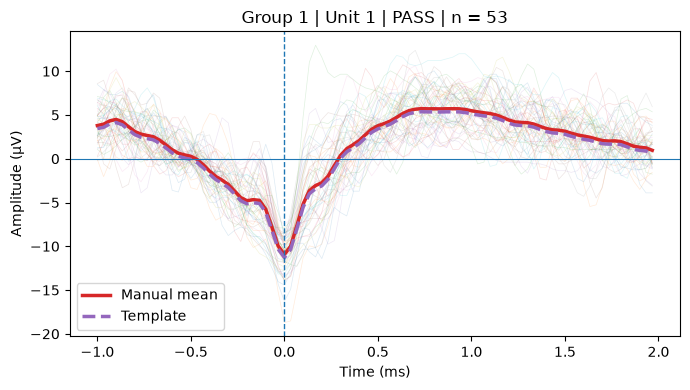

Group 3 | Unit 3 | PASS | n_spikes = 61 | shape = (61, 90)
template shape = (90,)


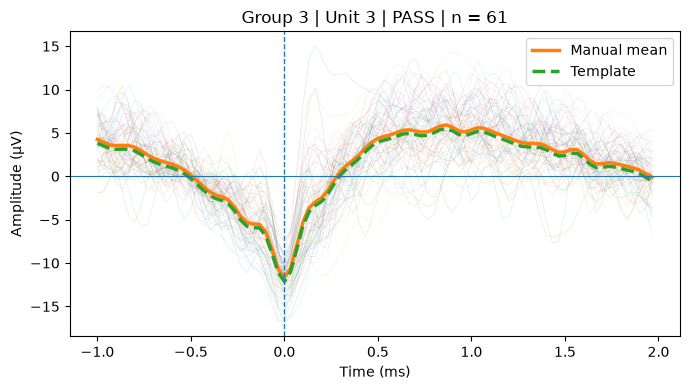

Group 4 | Unit 4 | PASS | n_spikes = 76 | shape = (76, 90)
template shape = (90,)


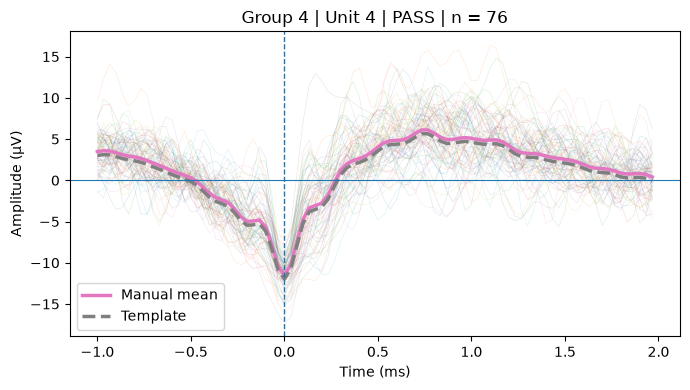

Group 7 | Unit 5 | PASS | n_spikes = 56 | shape = (56, 90)
template shape = (90,)


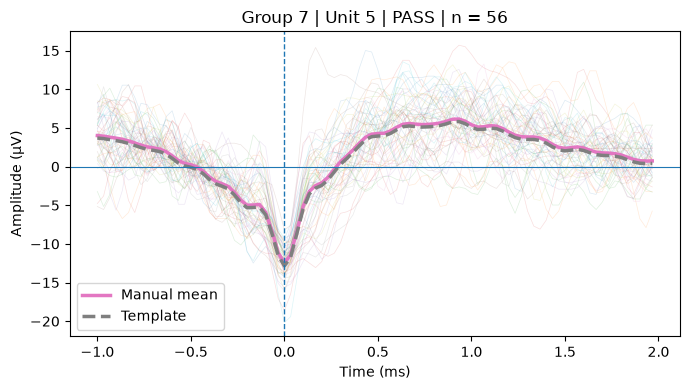

Group 9 | Unit 7 | PASS_LOW_CONFIDENCE | n_spikes = 36 | shape = (36, 90)
template shape = (90,)


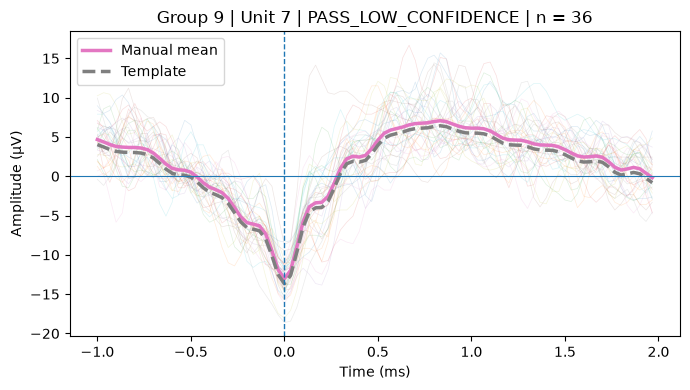

Group 10 | Unit 8 | PASS_LOW_CONFIDENCE | n_spikes = 30 | shape = (30, 90)
template shape = (90,)


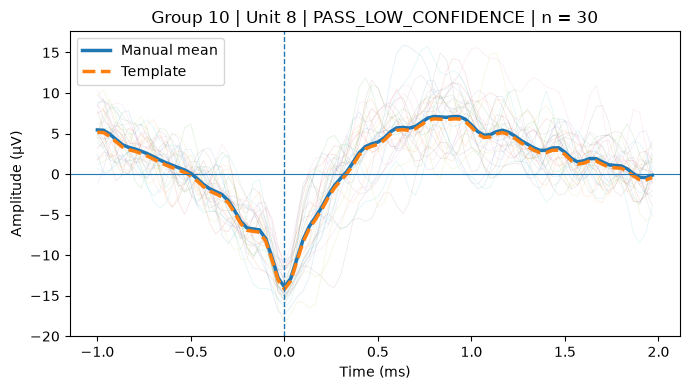

Group 12 | Unit 9 | PASS | n_spikes = 61 | shape = (61, 90)
template shape = (90,)


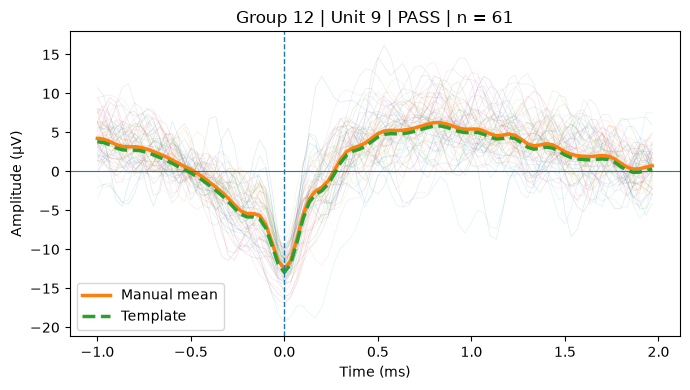

Group 14 | Unit 10 | PASS | n_spikes = 119 | shape = (119, 90)
template shape = (90,)


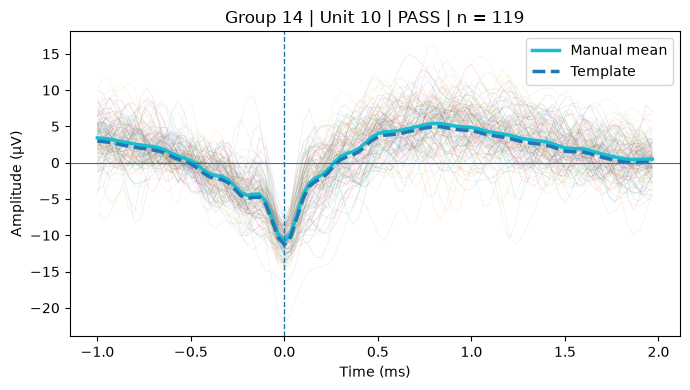

In [ ]:
pre_ms = 1.0
post_ms = 2.0

# ============================================================
# 1. 筛选所有通过 QC 的 units
# ============================================================

pass_table = qc_table[
    qc_table["qc_status"].isin([
        "PASS",
        "PASS_LOW_CONFIDENCE"
    ])
]

print(
    pass_table[
        ["group", "unit_id", "qc_status"]
    ]
)


# ============================================================
# 2. 遍历所有通过 QC 的 units
# ============================================================

for _, row in pass_table.iterrows():

    group_id = int(row["group"])
    unit_id = int(row["unit_id"])
    qc_status = row["qc_status"]

    # --------------------------------------------------------
    # 获取该 group 对应的 analyzer
    # --------------------------------------------------------

    analyzer = analyzers_by_group[group_id]

    rec = analyzer.recording
    sorting = analyzer.sorting

    fs = rec.get_sampling_frequency()

    # 获取当前 unit 的 spike train
    spikes = sorting.get_unit_spike_train(
        unit_id
    )

    pre = int(pre_ms / 1000 * fs)
    post = int(post_ms / 1000 * fs)

    manual_waveforms = []


    # ========================================================
    # 3. 提取每一个 spike 的 waveform
    # ========================================================

    for spike in spikes:

        start = int(spike) - pre
        end = int(spike) + post

        # 防止 waveform 超出 recording 边界
        if start < 0 or end > rec.get_num_frames():
            continue

        w = rec.get_traces(
            start_frame=start,
            end_frame=end,
            return_in_uV=True
        )[:, 0]

        # 去除每个 waveform 自己的局部 baseline
        baseline = np.median(
            w[:pre]
        )

        w = w - baseline

        manual_waveforms.append(w)


    manual_waveforms = np.asarray(
        manual_waveforms
    )


    # ========================================================
    # 4. 检查是否存在有效 waveform
    # ========================================================

    if len(manual_waveforms) == 0:

        print(
            f"Skip Group {group_id} | "
            f"Unit {unit_id}: "
            f"no valid waveforms"
        )

        continue


    print(
        f"Group {group_id} | "
        f"Unit {unit_id} | "
        f"{qc_status} | "
        f"n_spikes = {len(manual_waveforms)} | "
        f"shape = {manual_waveforms.shape}"
    )


    # ========================================================
    # 5. 建立时间轴
    # ========================================================

    time_ms = (
        np.arange(
            manual_waveforms.shape[1]
        ) - pre
    ) / fs * 1000


    # ========================================================
    # 6. 平均 waveform
    # ========================================================

    mean_waveform = np.mean(
        manual_waveforms,
        axis=0
    )


    # ========================================================
    # ★ 6.1 获取当前 unit 的 template
    # ========================================================

    templates_ext = analyzer.get_extension("templates")

    if templates_ext is None:
        raise RuntimeError(
            f"Group {group_id} 没有 templates extension"
        )

    template = templates_ext.get_unit_template(
        unit_id=unit_id,
        operator="average"
    )

    # 单通道：(n_samples, 1) -> (n_samples,)
    template = np.squeeze(template)

    # 与 manual waveform 使用相同的 baseline 处理
    template_baseline = np.median(
        template[:pre]
    )

    template = template - template_baseline

    print(
        f"template shape = {template.shape}"
    )


    # ========================================================
    # ★ 6.2 检查 template 与 manual waveform 长度
    # ========================================================

    if len(template) != len(time_ms):

        print(
            f"Warning: Group {group_id} | Unit {unit_id}: "
            f"template length = {len(template)}, "
            f"manual length = {len(time_ms)}"
        )

        template_can_plot = False

    else:

        template_can_plot = True


    # ========================================================
    # 7. 绘图
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )


    # --------------------------------------------------------
    # 单个 spike waveform
    # --------------------------------------------------------

    for w in manual_waveforms:

        ax.plot(
            time_ms,
            w,
            linewidth=0.5,
            alpha=0.15
        )


    # --------------------------------------------------------
    # manual mean waveform
    # --------------------------------------------------------

    ax.plot(
        time_ms,
        mean_waveform,
        linewidth=2.5,
        label="Manual mean"
    )


    # --------------------------------------------------------
    # ★ template
    # --------------------------------------------------------

    if template_can_plot:

        ax.plot(
            time_ms,
            template,
            linewidth=2.5,
            linestyle="--",
            label="Template"
        )


    # --------------------------------------------------------
    # spike 对齐时刻
    # --------------------------------------------------------

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )


    # --------------------------------------------------------
    # baseline
    # --------------------------------------------------------

    ax.axhline(
        0,
        linewidth=0.8
    )


    ax.set_xlabel(
        "Time (ms)"
    )

    ax.set_ylabel(
        "Amplitude (µV)"
    )

    ax.set_title(
        f"Group {group_id} | "
        f"Unit {unit_id} | "
        f"{qc_status} | "
        f"n = {len(manual_waveforms)}"
    )

    # ★ 显示 Manual mean / Template
    ax.legend()


    plt.tight_layout()
    plt.show()

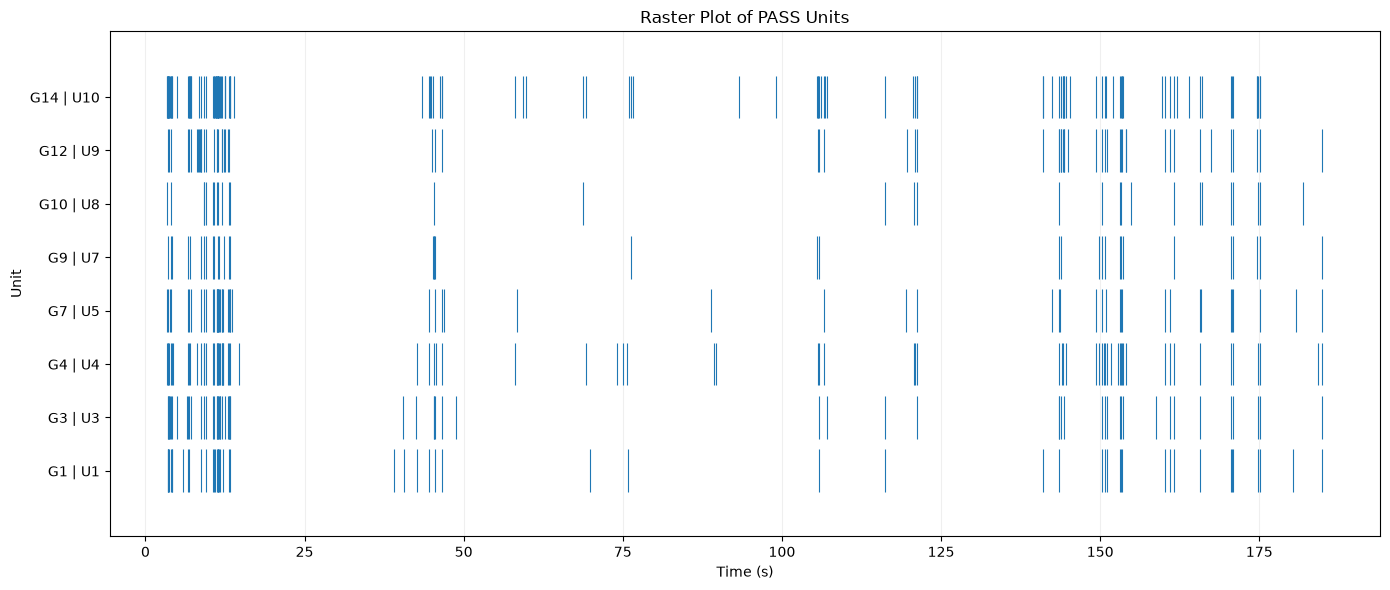

In [174]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. 筛选通过 QC 的 units
# ============================================================

pass_table = qc_table[
    qc_table["qc_status"].isin([
        "PASS",
        "PASS_LOW_CONFIDENCE"
    ])
].copy()


# ============================================================
# 2. 创建 raster plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 6)
)

y_position = 0
y_ticks = []
y_labels = []


# ============================================================
# 3. 遍历各个通过 QC 的 unit
# ============================================================

for _, row in pass_table.iterrows():

    group_id = int(row["group"])
    unit_id = int(row["unit_id"])
    qc_status = row["qc_status"]

    analyzer = analyzers_by_group[group_id]

    sorting = analyzer.sorting
    rec = analyzer.recording

    fs = rec.get_sampling_frequency()

    # --------------------------------------------------------
    # 获取 spike train
    # --------------------------------------------------------

    spikes = sorting.get_unit_spike_train(
        unit_id
    )

    # sample index → seconds
    spike_times = spikes / fs


    # --------------------------------------------------------
    # Raster
    # --------------------------------------------------------

    ax.eventplot(
        spike_times,
        lineoffsets=y_position,
        linelengths=0.8,
        linewidths=0.8
    )


    # --------------------------------------------------------
    # Y轴标签
    # --------------------------------------------------------

    y_ticks.append(y_position)

    y_labels.append(
        f"G{group_id} | U{unit_id}"
    )

    y_position += 1


# ============================================================
# 4. 图形设置
# ============================================================

ax.set_yticks(
    y_ticks
)

ax.set_yticklabels(
    y_labels
)

ax.set_xlabel(
    "Time (s)"
)

ax.set_ylabel(
    "Unit"
)

ax.set_title(
    "Raster Plot of PASS Units"
)

ax.grid(
    axis="x",
    alpha=0.2
)

plt.tight_layout()
plt.show()